# TNG300：恒星質量のみ vs 恒星質量＋10 cMpc周辺銀河数

09の銀河重み付き条件付きKDEを拡張し、同じ標本・同じホスト分割・同じCV/test評価点で比較します。
実データでの結果は未実行です。公式TNG JupyterLabで上から実行してください。

- 対象：5≤z≤9（補間用隣接時刻を含む）、Mstar≥10^9 Msun、z=0まで追跡成功の中心・衛星銀河。
- 環境：対象銀河のSubhaloPosを中心とする **r<10 cMpcの3D球**。周期境界を適用。
- トレーサー：同時刻のSubhaloFlag=1、**Mstar>10^8 Msun** の全保存銀河。追跡成功やtrain/testで制限しません。
- 自分自身だけをSubhaloIDで除外。同じFoFの他の銀河は含めます。
- 入力：(logMstar) または (logMstar, ln(1+Ngal10))。Ngal10は非負整数、0も有効。

半径とトレーサー閾値は事前固定です。07のFoF中心・初期ハロー質量選択とは標本も開口中心も異なります。
観測誤差・観測selectionは含みません。ホスト分割後も環境の重なりや空間相関は残ります。
近傍銀河の位置・質量は使いますが、その最終ホスト質量は環境計算には使いません。


## 共通処理・09のカタログ構築／再開処理
既存の09のカタログ保存先を使用します。同じ入力ファイル・保存下限ならCSVと追跡チェックポイントを再利用します。

In [1]:
"""TNG300 galaxy-weighted empirical Bayes, latent properties, version 1.
No TNG data are read at import. All output writes require explicit function calls.
"""
from pathlib import Path
from collections import OrderedDict
import hashlib
import json
import sqlite3
import warnings
import numpy as np
import pandas as pd
from scipy.special import logsumexp, ndtr
from scipy.optimize import brentq
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

VERSION = 'latent-host-v1'
LOG2PI = np.log(2 * np.pi)


def digest_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1024 * 1024), b''):
            h.update(b)
    return h.hexdigest()


def atomic_csv(frame, path):
    path = Path(path)
    tmp = path.with_suffix(path.suffix + '.tmp')
    frame.to_csv(tmp, index=False)
    tmp.replace(path)


def discover_base():
    import os
    if os.environ.get('TNG_OUTPUT_DIR'):
        p = Path(os.environ['TNG_OUTPUT_DIR']).expanduser()
        if not p.is_dir():
            raise FileNotFoundError(p)
        return p.resolve()
    roots = [Path.cwd(), *Path.cwd().parents, Path('/home/tnguser')]
    for root in roots:
        for name in ['TNG300-1', 'L205n2500TNG']:
            p = root / 'sims.TNG' / name / 'output'
            if p.is_dir():
                return p.resolve()
    raise FileNotFoundError('Set TNG_OUTPUT_DIR to the TNG300-1 output directory.')


def discover_epochs(base):
    """All snapshots within 5<=z<=9 plus one bracketing snapshot on each side."""
    import illustris_python as il
    rows = []
    for snap in range(100):
        h = il.groupcat.loadHeader(str(base), snap)
        rows.append((snap, float(h['Redshift'])))
        if rows[-1][1] < 5:
            break
    tab = pd.DataFrame(rows, columns=['snapshot', 'redshift'])
    inside = tab.redshift.between(5, 9)
    selected = set(tab.loc[inside, 'snapshot'].astype(int))
    selected.add(int(tab.loc[tab.redshift.gt(9)].iloc[-1].snapshot))
    selected.add(int(tab.loc[tab.redshift.lt(5)].iloc[0].snapshot))
    return tab[tab.snapshot.isin(selected)].sort_values('snapshot').reset_index(drop=True)




In [2]:
class RootTracker:
    """Read the endpoint directly; RootDescendantID follows the descendant chain.

    SubLink tree IDs are contiguous within a tree/file. Verify both seed and root.
    Unlike onlyMDB, this avoids reading a large intervening off-main-branch subtree.
    I/O/structure errors deliberately propagate; they are not called missing descendants.
    """
    def __init__(self, base):
        import illustris_python as il
        self.il, self.base = il, str(base)
        self.offsets = np.asarray(il.sublink.subLinkOffsets(self.base, 'SubLink'), dtype=np.int64)
        self.handles = OrderedDict()

    def handle(self, chunk):
        import h5py
        if chunk not in self.handles:
            self.handles[chunk] = h5py.File(self.il.sublink.treePath(self.base, 'SubLink', chunk), 'r')
            if len(self.handles) > 8:
                self.handles.popitem(last=False)[1].close()
        self.handles.move_to_end(chunk)
        return self.handles[chunk]

    def trace(self, snap, sid):
        row, _, tree_id = map(int, self.il.sublink.treeOffsets(self.base, int(snap), int(sid), 'SubLink'))
        if row < 0:
            return {'TrackingStatus': 'not_in_tree', 'SubhaloID_z0': -1, 'TerminalSnap': -1}
        chunk = int(np.searchsorted(self.offsets, row, side='right') - 1)
        if chunk < 0:
            raise ValueError('Invalid tree offset')
        f = self.handle(chunk)
        local = row - int(self.offsets[chunk])
        if not 0 <= local < len(f['SubhaloID']):
            raise ValueError('Seed outside file')
        if (int(f['SubhaloID'][local]) != tree_id or int(f['SnapNum'][local]) != snap
                or int(f['SubfindID'][local]) != sid):
            raise ValueError('SubLink seed mismatch')
        root_id = int(f['RootDescendantID'][local])
        root_row = local + root_id - tree_id
        if not 0 <= root_row < len(f['SubhaloID']) or int(f['SubhaloID'][root_row]) != root_id:
            raise ValueError('RootDescendantID/row mismatch')
        end_snap = int(f['SnapNum'][root_row])
        if end_snap < snap or end_snap > 99:
            raise ValueError('Invalid terminal snapshot')
        return {'TrackingStatus': 'success' if end_snap == 99 else 'terminated_before_z0',
                'SubhaloID_z0': int(f['SubfindID'][root_row]) if end_snap == 99 else -1,
                'TerminalSnap': end_snap}

    def close(self):
        for f in self.handles.values():
            f.close()
        self.handles.clear()


def build_catalog(base, out, archive_logmstar_min=8.0, crosscheck_n=5):
    """All physical galaxies (centrals AND satellites), no initial halo-mass cut.

    SubhaloMassType[:,4] = total bound stellar mass; SubhaloSFR = total bound SFR.
    Archive >=1e8 Msun, inference defaults to >=1e9. Neither is a completeness claim.
    Immutable, fingerprinted per-snapshot CSVs; resumable per-seed SQLite checkpoint.
    """
    import glob
    import illustris_python as il
    from tqdm.auto import tqdm
    base, out = Path(base).resolve(), Path(out)
    out.mkdir(parents=True, exist_ok=True)
    epochs = discover_epochs(base)
    head = il.groupcat.loadHeader(str(base), 99)
    h = float(head['HubbleParam'])
    if not (np.isclose(h, .6774, atol=1e-4) and np.isclose(float(head['BoxSize']), 205000)):
        raise ValueError('Expected TNG300 geometry/cosmology')
    # Header particle count distinguishes TNG300-1 from the lower resolutions.
    import h5py
    from illustris_python.snapshot import snapPath
    with h5py.File(snapPath(str(base), int(epochs.iloc[0].snapshot)), 'r') as f:
        n_dm = int(f['Header'].attrs['NumPart_Total'][1])
        high = f['Header'].attrs.get('NumPart_Total_HighWord', np.zeros(6, dtype=np.uint32))
        n_dm += int(high[1]) << 32
    if n_dm != 2500**3:
        raise ValueError(f'Expected TNG300-1 DM count; found {n_dm}')
    paths = glob.glob(il.sublink.treePath(str(base), 'SubLink', '*'))
    for sn in [*epochs.snapshot.astype(int), 99]:
        gc = il.groupcat.gcPath(str(base), sn)
        paths.extend(glob.glob(str(Path(gc).parent / '*.hdf5')))
        paths.append(il.groupcat.offsetPath(str(base), sn))
    stats = [[str(Path(p).resolve()), Path(p).stat().st_size, Path(p).stat().st_mtime_ns]
             for p in sorted(set(paths))]
    meta = dict(version=VERSION, base=str(base), epochs=epochs.to_dict('records'),
                archive_logmstar_min=float(archive_logmstar_min), h=h,
                selection='SubhaloFlag == 1; total stellar mass >= floor; all centrals and satellites',
                mstar_field='SubhaloMassType[:,4]', sfr_field='SubhaloSFR',
                target='z=0 FoF Group_M_Crit200 of SubLink root descendant', files=stats)
    signature = hashlib.sha256(json.dumps(meta, sort_keys=True).encode()).hexdigest()
    cache_dir = out / ('catalog_' + signature[:16])
    cache_dir.mkdir(exist_ok=True)
    (cache_dir / 'manifest.json').write_text(json.dumps(meta, indent=2))
    z0_group = np.asarray(il.groupcat.loadSubhalos(str(base), 99, fields='SubhaloGrNr'), dtype=np.int64)
    z0_mass = np.asarray(il.groupcat.loadHalos(str(base), 99, fields='Group_M_Crit200')) * 1e10 / h
    conn = sqlite3.connect(cache_dir / 'tracking.sqlite')
    conn.execute('CREATE TABLE IF NOT EXISTS traces (snap INTEGER, sid INTEGER, payload TEXT, PRIMARY KEY(snap,sid))')
    tracker = RootTracker(base)
    frames = []
    try:
        for ep in epochs.itertuples(index=False):
            snap, z = int(ep.snapshot), float(ep.redshift)
            path = cache_dir / f'galaxies_{snap:03d}.csv'
            if path.exists():
                frames.append(pd.read_csv(path))
                continue
            fields = ['SubhaloMassType', 'SubhaloSFR', 'SubhaloFlag', 'SubhaloGrNr',
                      'SubhaloLenType', 'SubhaloPos']
            cat = il.groupcat.loadSubhalos(str(base), snap, fields=fields)
            first = np.asarray(il.groupcat.loadHalos(str(base), snap, fields='GroupFirstSub'))
            mass = np.asarray(cat['SubhaloMassType'][:, 4], float) * 1e10 / h
            selected = np.flatnonzero((np.asarray(cat['SubhaloFlag']) == 1) & np.isfinite(mass)
                                      & (mass >= 10**archive_logmstar_min))
            done = {int(s): json.loads(p) for s, p in conn.execute('SELECT sid,payload FROM traces WHERE snap=?', (snap,))}
            rows = []
            # Deterministic random seed checks include non-main progenitors when present.
            check_ids = set(np.random.default_rng(42 + snap).choice(selected, min(crosscheck_n, len(selected)), replace=False))
            for k, sid in enumerate(tqdm(selected, desc=f'snap={snap} z={z:.3f}')):
                sid = int(sid)
                r = done.get(sid)
                if r is None:
                    r = tracker.trace(snap, sid)
                    conn.execute('INSERT OR REPLACE INTO traces VALUES (?,?,?)', (snap, sid, json.dumps(r)))
                    if k % 100 == 0:
                        conn.commit()
                if sid in check_ids:
                    t = il.sublink.loadTree(str(base), snap, sid, fields=['SnapNum', 'SubfindID'], onlyMDB=True)
                    end = np.array([], dtype=int) if t is None else np.flatnonzero(np.asarray(t['SnapNum']) == 99)
                    if r['TrackingStatus'] == 'success':
                        if len(end) != 1 or int(t['SubfindID'][end[0]]) != r['SubhaloID_z0']:
                            raise ValueError('Endpoint crosscheck failed')
                    elif len(end):
                        raise ValueError('Unexpected z0 endpoint in crosscheck')
                gr = int(cat['SubhaloGrNr'][sid])
                if not 0 <= gr < len(first):
                    raise ValueError('Invalid source host ID')
                gr0, m0 = -1, np.nan
                r = dict(r)
                if r['TrackingStatus'] == 'success':
                    s0 = r['SubhaloID_z0']
                    if not 0 <= s0 < len(z0_group):
                        raise ValueError('Invalid descendant subhalo')
                    gr0 = int(z0_group[s0])
                    if not 0 <= gr0 < len(z0_mass):
                        raise ValueError('Invalid descendant host')
                    m0 = float(z0_mass[gr0])
                    if not np.isfinite(m0) or m0 <= 0:
                        r['TrackingStatus'] = 'invalid_host_mass'
                        m0 = np.nan
                sfr = float(cat['SubhaloSFR'][sid])
                pos = np.asarray(cat['SubhaloPos'][sid]) / (1000 * h)
                rows.append(dict(snapshot=snap, redshift=z, SubhaloID=sid, GroupID=gr,
                                 is_central=bool(first[gr] == sid), logMstar=float(np.log10(mass[sid])),
                                 SFR=sfr if np.isfinite(sfr) and sfr >= 0 else np.nan,
                                 Nstar=int(cat['SubhaloLenType'][sid, 4]),
                                 x_cMpc=pos[0], y_cMpc=pos[1], z_cMpc=pos[2],
                                 GroupID_z0=gr0, logM0=np.log10(m0) if m0 > 0 else np.nan, **r))
            frame = pd.DataFrame(rows)
            if frame.empty:
                raise RuntimeError(f'No selected galaxies at snapshot {snap}')
            atomic_csv(frame, path)
            frames.append(frame)
            conn.commit()
        combined = pd.concat(frames, ignore_index=True)
        if combined.duplicated(['snapshot', 'SubhaloID']).any():
            raise ValueError('Duplicate source galaxies')
        atomic_csv(combined, cache_dir / 'galaxies_all.csv')
        return combined, cache_dir
    finally:
        conn.commit()
        conn.close()
        tracker.close()




In [3]:
def prepare_sample(catalog, logmstar_min=9.0):
    """Track missing descendants explicitly; inference is conditional on successful tracking."""
    d = catalog.loc[catalog.logMstar.ge(logmstar_min)].copy()
    if d.empty:
        raise ValueError('Empty stellar-mass selection')
    d['mass_bin'] = np.floor(d.logMstar * 2) / 2
    d['tracked'] = d.TrackingStatus.eq('success') & np.isfinite(d.logM0) & d.GroupID_z0.ge(0)
    report = d.groupby(['snapshot', 'redshift', 'mass_bin'], observed=True).agg(
        N=('tracked', 'size'), N_tracked=('tracked', 'sum'), tracking_fraction=('tracked', 'mean'),
        median_Nstar=('Nstar', 'median')).reset_index()
    if (report.tracking_fraction < .95).any():
        warnings.warn('Some mass/redshift bins have <95% tracking success. Inspect completeness.csv; '
                      'posterior is conditional on successful tracking and is not corrected for missing descendants.')
    valid = d.loc[d.tracked].copy()
    if valid.empty:
        raise ValueError('No valid descendants')
    if not np.isfinite(valid.Ngal10).all() or (valid.Ngal10 < 0).any():
        raise ValueError('Invalid environment count; do not alter the common sample')
    valid['log1pNgal10'] = np.log1p(valid.Ngal10)
    valid['GroupID_z0'] = valid.GroupID_z0.astype(np.int64)
    return valid.reset_index(drop=True), report


def host_split(frame, test_fraction=.2, seed=42):
    splitter = GroupShuffleSplit(n_splits=1, test_size=test_fraction, random_state=seed)
    i, j = next(splitter.split(frame, groups=frame.GroupID_z0))
    train, test = frame.iloc[i].copy(), frame.iloc[j].copy()
    assert set(train.GroupID_z0).isdisjoint(test.GroupID_z0)
    # One global split across ALL epochs, so progenitors at different z cannot leak.
    for sn in frame.snapshot.unique():
        if train[train.snapshot.eq(sn)].GroupID_z0.nunique() < 6 or test[test.snapshot.eq(sn)].empty:
            raise ValueError(f'Insufficient host support at snapshot {sn}')
    return train, test




## 環境量の構築と別キャッシュ
元の銀河カタログは変更しません。元CSVのハッシュ、開口定義、環境コード版を保存先IDに含め、snapshot/SubhaloIDで一対一結合します。

In [4]:
ENVIRONMENT_SPEC = dict(version='ngal10-v1', radius_cMpc=10.0,
                        tracer_logMstar_gt=8.0, center='SubhaloPos',
                        exclude='self SubhaloID only', boundary='periodic; r < R')


def count_neighbors(target, tracers, boxsize, radius=10.0):
    from scipy.spatial import cKDTree
    poscols = ['x_cMpc', 'y_cMpc', 'z_cMpc']
    tp = target[poscols].to_numpy(float)
    gp = tracers[poscols].to_numpy(float)
    if not np.isfinite(tp).all() or not np.isfinite(gp).all():
        raise ValueError('Nonfinite environment positions')
    if target.SubhaloID.duplicated().any() or tracers.SubhaloID.duplicated().any():
        raise ValueError('Duplicate IDs within epoch')
    if not np.isfinite(boxsize) or boxsize <= 2*radius or radius <= 0:
        raise ValueError('Invalid box/radius')
    if not len(tracers):
        return np.zeros(len(target), dtype=np.int64)
    tree = cKDTree(np.mod(gp, boxsize), boxsize=boxsize)
    counts = np.empty(len(target), dtype=np.int64)
    # Count-only queries avoid materializing potentially huge neighbor lists.
    for start in range(0, len(target), 4096):
        stop = min(start+4096, len(target))
        counts[start:stop] = tree.query_ball_point(
            np.mod(tp[start:stop], boxsize), r=np.nextafter(radius, 0.), return_length=True)
    # Both tables originate from the same per-epoch catalog; self positions coincide.
    counts -= target.SubhaloID.isin(tracers.SubhaloID).to_numpy(dtype=np.int64)
    if (counts < 0).any():
        raise ValueError('Negative count after self exclusion')
    return counts


def add_environment(catalog, catalog_dir, out, base):
    import illustris_python as il
    if catalog.duplicated(['snapshot', 'SubhaloID']).any():
        raise ValueError('Duplicate catalog keys')
    manifest = json.loads((Path(catalog_dir)/'manifest.json').read_text())
    if manifest['archive_logmstar_min'] > ENVIRONMENT_SPEC['tracer_logMstar_gt']:
        raise ValueError('Archive does not reach tracer mass threshold')
    box = float(il.groupcat.loadHeader(str(base), 99)['BoxSize'])/(1000*manifest['h'])
    spec = dict(**ENVIRONMENT_SPEC, catalog_sha256=digest_file(Path(catalog_dir)/'galaxies_all.csv'),
                boxsize_cMpc=box)
    key = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:16]
    envdir = Path(out)/('environment_'+key)
    envdir.mkdir(parents=True, exist_ok=True)
    (envdir/'manifest.json').write_text(json.dumps(spec, indent=2))
    parts = []
    for snap, group in catalog.groupby('snapshot', sort=True):
        path = envdir/f'environment_{int(snap):03d}.csv'
        if path.exists():
            frame = pd.read_csv(path)
        else:
            tracers = group.loc[group.logMstar.gt(spec['tracer_logMstar_gt'])]
            frame = group[['snapshot','SubhaloID']].copy()
            frame['Ngal10'] = count_neighbors(group, tracers, box, spec['radius_cMpc'])
            atomic_csv(frame, path)
        parts.append(frame)
        print(f'Environment snapshot {snap}: {len(frame):,} galaxies', flush=True)
    env = pd.concat(parts, ignore_index=True)
    merged = catalog.merge(env, on=['snapshot','SubhaloID'], how='left', validate='one_to_one')
    if len(env) != len(catalog) or merged.Ngal10.isna().any():
        raise ValueError('Incomplete environment cache')
    v = merged.Ngal10.to_numpy(float)
    if not np.isfinite(v).all() or (v < 0).any() or (v != np.floor(v)).any():
        raise ValueError('Invalid cached environment counts')
    merged['Ngal10'] = v.astype(np.int64)
    return merged, envdir, spec


## KDEと帯域幅選択
恒星質量のみは09と同じ9候補。環境付きは恒星質量幅0.1/0.2/0.4 dex、ln(1+N)幅0.25/0.5/1.0、出力幅0.10/0.20/0.35 dexの27候補。環境幅は独立に探索します。
3-foldホストCVで時刻ごとの平均NLLを等重みで最小化します。疎な時刻は全候補で共通して除外し、選んだ幅を転用します。testは選択に使いません。

In [5]:
class Posterior:
    """Gaussian mixture density in m=log10(M0/Msun), NOT density per linear mass."""
    def __init__(self, means, weights, width, hosts, metadata=None):
        self.means, self.weights = np.asarray(means, float), np.asarray(weights, float)
        self.width = float(width)
        self.hosts = np.asarray(hosts)
        if (len(self.means) == 0 or self.means.shape != self.weights.shape or len(self.hosts) != len(self.means)
                or not np.isfinite(self.means).all() or not np.isfinite(self.weights).all()
                or (self.weights < 0).any() or self.weights.sum() <= 0
                or not np.isfinite(width) or width <= 0):
            raise ValueError('Invalid mixture')
        self.weights = self.weights / self.weights.sum()
        self.metadata = metadata or {}

    def cdf(self, m):
        return float(np.dot(self.weights, ndtr((float(m) - self.means) / self.width)))

    def logpdf(self, m):
        with np.errstate(divide='ignore'):
            lw = np.log(self.weights)
        return float(logsumexp(lw - .5 * ((float(m) - self.means) / self.width)**2)
                     - np.log(self.width) - .5 * LOG2PI)

    def quantile(self, q):
        if not 0 < q < 1:
            raise ValueError('Quantile must lie strictly between 0 and 1')
        return brentq(lambda m: self.cdf(m) - q, self.means.min() - 12*self.width,
                      self.means.max() + 12*self.width)

    def summary(self):
        wh = pd.Series(self.weights).groupby(self.hosts).sum().to_numpy()
        return dict(q025=self.quantile(.025), q16=self.quantile(.16), median=self.quantile(.5),
                    q84=self.quantile(.84), q975=self.quantile(.975),
                    p_ge_1e13=1-self.cdf(13), p_ge_1e14=1-self.cdf(14), p_ge_1e15=1-self.cdf(15),
                    ESS_galaxy=1/np.sum(self.weights**2), ESS_host=1/np.sum(wh**2), **self.metadata)

    def table(self, n=600):
        grid = np.linspace(self.means.min()-8*self.width, self.means.max()+8*self.width, n)
        return pd.DataFrame({'logM0': grid, 'pdf_per_dex': [np.exp(self.logpdf(x)) for x in grid],
                             'cdf': [self.cdf(x) for x in grid]})


def conditional(frame, query, bandwidths, ywidth, check_support=True):
    """Condition a product-Gaussian joint KDE on exact latent values.

    Equal weights on source GALAXIES are the prior. Kernel bandwidth is statistical
    smoothing, not a measurement error. Omitted environment is analytically marginalized.
    """
    cols = list(query)
    if not cols or set(cols) - {'logMstar', 'log1pNgal10'}:
        raise ValueError('Unsupported or empty latent query')
    x, q = frame[cols].to_numpy(float), np.array([query[k] for k in cols], float)
    bw = np.array([bandwidths[k] for k in cols], float)
    if len(x) == 0 or not np.isfinite(x).all() or not np.isfinite(q).all() or (bw <= 0).any():
        raise ValueError('Invalid query, bandwidth or empty sample')
    distance2 = np.sum(((x-q)/bw)**2, axis=1)
    logw = -.5 * distance2
    w = np.exp(logw-logsumexp(logw))
    host_w = pd.Series(w).groupby(frame.GroupID_z0.to_numpy()).sum().to_numpy()
    diagnostics = dict(nearest_kernel_distance=float(np.sqrt(distance2.min())),
                       ESS_galaxy=1/np.sum(w*w), ESS_host=1/np.sum(host_w*host_w))
    outside = np.any(q < x.min(axis=0)) or np.any(q > x.max(axis=0))
    poor = outside or diagnostics['nearest_kernel_distance'] > 3 or diagnostics['ESS_host'] < 10 or diagnostics['ESS_galaxy'] < 20
    if check_support and poor:
        raise ValueError(f'Insufficient support / extrapolation: {diagnostics}; query outside range={outside}. '
                         'Use a broader catalog or inspect explicitly; do not report this as a reliable posterior.')
    return Posterior(frame.logM0.to_numpy(), w, ywidth, frame.GroupID_z0.to_numpy(),
                     {'support_ok': bool(not poor), 'outside_range': bool(outside), **diagnostics})




In [6]:
FEATURE_SETS = {'mstar': ['logMstar'], 'mstar_ngal10': ['logMstar', 'log1pNgal10']}
BASE_BW = {'logMstar': .2, 'log1pNgal10': .5}


def select_bandwidths(train, validation_cap_per_snap=100, seed=42, diagnostics_path=None):
    """3 host folds; minimize conditional negative log density of logM0.

    Validation cap is a deterministic random subset, shared by all candidates.
    Equal mean weight per epoch prevents snapshot abundance from choosing the model.
    No test galaxies are used. Separate tuning for the two feature sets.
    Only epochs supported in ALL folds enter CV; omitted epochs remain in the model.
    Bandwidths at omitted epochs are transferred, not validated by this CV.
    """
    splits = list(GroupKFold(3).split(train, groups=train.GroupID_z0))
    diagnostics = []
    for fold, (it, iv) in enumerate(splits):
        tr, va = train.iloc[it], train.iloc[iv]
        for snap in sorted(train.snapshot.unique()):
            a = tr.loc[tr.snapshot.eq(snap)]
            b = va.loc[va.snapshot.eq(snap)]
            diagnostics.append(dict(
                fold=fold, snapshot=int(snap),
                redshift=float(train.loc[train.snapshot.eq(snap), 'redshift'].iloc[0]),
                N_train=len(a), N_validation=len(b),
                N_hosts_train=a.GroupID_z0.nunique(), N_hosts_validation=b.GroupID_z0.nunique(),
                fold_ok=len(a) >= 20 and not b.empty))
    diagnostics = pd.DataFrame(diagnostics)
    eligible = diagnostics.groupby('snapshot').fold_ok.all()
    cv_epochs = eligible.index[eligible].tolist()
    diagnostics['used_for_cv'] = diagnostics.snapshot.isin(cv_epochs)
    diagnostics['reason'] = np.where(
        diagnostics.used_for_cv, 'included',
        'excluded from all folds: at least one fold has N_train < 20 or N_validation == 0')
    if diagnostics_path is not None:
        diagnostics.to_csv(diagnostics_path, index=False)
    excluded = eligible.index[~eligible].tolist()
    if excluded:
        warnings.warn(f'CV excludes snapshots {excluded} from ALL candidates/folds. '
                      'Their model bandwidths are transferred from supported epochs; '
                      'inspect cv_fold_diagnostics.csv and per-snapshot test support.')
    if not cv_epochs:
        raise ValueError('No snapshot supports 3-fold host CV. Inspect fold diagnostics; '
                         'revise the population selection or CV design.')
    records = []
    for name, cols in FEATURE_SETS.items():
        from itertools import product
        env_scales = [.5, 1., 2.] if 'log1pNgal10' in cols else [1.]
        for scale, env_scale, yw in product([.5, 1., 2.], env_scales, [.10, .20, .35]):
            bw = {'logMstar': .2*scale, 'log1pNgal10': .5*env_scale}
            for fold, (it, iv) in enumerate(splits):
                tr, va = train.iloc[it], train.iloc[iv]
                assert set(tr.GroupID_z0).isdisjoint(va.GroupID_z0)
                for snap in cv_epochs:
                    a = tr.loc[tr.snapshot.eq(snap)]
                    b = va.loc[va.snapshot.eq(snap)]
                    if len(a) < 20 or b.empty:
                        raise ValueError(f'Too few training/validation galaxies at {snap}')
                    b = b.sample(min(validation_cap_per_snap, len(b)), random_state=seed+fold+int(snap))
                    loss = []
                    for _, row in b.iterrows():
                        p = conditional(a, row[cols].to_dict(), bw, yw, check_support=False)
                        loss.append(-p.logpdf(row.logM0))
                    records.append(dict(feature_set=name, scale=scale, env_scale=env_scale, ywidth=yw, fold=fold,
                                        snapshot=int(snap), n=len(loss), nll=float(np.mean(loss))))
            print(f'CV {name}: scale={scale}, env_scale={env_scale}, target_width={yw} complete', flush=True)
    cv = pd.DataFrame(records)
    selected = {}
    for name in FEATURE_SETS:
        scores = cv[cv.feature_set.eq(name)].groupby(['scale', 'env_scale', 'ywidth']).nll.mean()
        scale, env_scale, yw = scores.idxmin()
        selected[name] = {'bandwidths': {'logMstar': .2*float(scale), 'log1pNgal10': .5*float(env_scale)},
                          'ywidth': float(yw), 'cv_nll': float(scores.min())}
    return selected, cv, diagnostics


def evaluate(train, test, selected, test_cap_per_snap=300, seed=777):
    """Frozen test diagnostics. PIT intervals assess central 68/95% coverage.

    No claim of independent rows across snapshots or shared final hosts.
    Sparse/unsupported test queries remain included and are visibly flagged.
    """
    rows = []
    for snap in sorted(test.snapshot.unique()):
        a = train[train.snapshot.eq(snap)]
        b = test[test.snapshot.eq(snap)]
        b = b.sample(min(test_cap_per_snap, len(b)), random_state=seed+int(snap))
        for name, cols in FEATURE_SETS.items():
            cfg = selected[name]
            for _, row in b.iterrows():
                p = conditional(a, row[cols].to_dict(), cfg['bandwidths'], cfg['ywidth'], check_support=False)
                width68 = p.quantile(.84)-p.quantile(.16)
                pit = p.cdf(row.logM0)
                prior = Posterior(a.logM0.to_numpy(), np.ones(len(a)), cfg['ywidth'], a.GroupID_z0.to_numpy())
                prob = 1-p.cdf(14)
                rows.append(dict(feature_set=name, snapshot=int(snap), redshift=row.redshift,
                                 SubhaloID=int(row.SubhaloID), GroupID_z0=int(row.GroupID_z0),
                                 logMstar=row.logMstar, Ngal10=int(row.Ngal10), logM0=row.logM0, pit=pit, W68_dex=width68,
                                 nll=-p.logpdf(row.logM0), prior_nll=-prior.logpdf(row.logM0),
                                 coverage68=.16 <= pit <= .84, coverage95=.025 <= pit <= .975,
                                 p_cluster=prob, brier=(prob-float(row.logM0>=14))**2,
                                 support_ok=p.metadata['support_ok']))
    raw = pd.DataFrame(rows)
    summary = raw.groupby(['feature_set', 'snapshot', 'redshift']).agg(
        N=('pit','size'), N_hosts=('GroupID_z0','nunique'), NLL=('nll','mean'),
        prior_NLL=('prior_nll','mean'), coverage68=('coverage68','mean'), coverage95=('coverage95','mean'),
        W68_dex=('W68_dex','mean'), Brier=('brier','mean'), supported_fraction=('support_ok','mean')).reset_index()
    return raw, summary




In [7]:
class LatentHostModel:
    def __init__(self, train, selected, logmstar_min=9.):
        self.train = train.copy()
        self.selected, self.logmstar_min = selected, float(logmstar_min)
        self.epochs = train[['snapshot', 'redshift']].drop_duplicates().sort_values('redshift')
        if self.epochs.snapshot.duplicated().any() or self.epochs.redshift.duplicated().any():
            raise ValueError('Ambiguous snapshot/redshift mapping')

    def posterior(self, z, logMstar, ngal=None, check_support=True):
        """z in [5,9]; exact latent stellar mass in log10 Msun, Ngal10 is an integer count in a 10 cMpc sphere.

        check_support=False is diagnostic-only; support_ok remains false if unsupported.

        At non-snapshot redshifts, linearly mix the TWO normalized conditional
        distributions in scale factor a=1/(1+z). This is an explicit interpolation
        approximation, NOT extra independent data and NOT a redshift likelihood.
        """
        vals = [z, logMstar] if ngal is None else [z, logMstar, ngal]
        if not np.isfinite(vals).all() or not 5 <= z <= 9 or logMstar < self.logmstar_min:
            raise ValueError(f'Use 5<=z<=9, logMstar>={self.logmstar_min}, finite latent values')
        if ngal is not None and (not float(ngal).is_integer() or ngal < 0):
            raise ValueError('Ngal10 must be a nonnegative integer; zero is valid')
        name = 'mstar' if ngal is None else 'mstar_ngal10'
        query = {'logMstar': float(logMstar)}
        if ngal is not None:
            query['log1pNgal10'] = float(np.log1p(ngal))
        cfg = self.selected[name]
        zs = self.epochs.redshift.to_numpy()
        exact = np.flatnonzero(np.isclose(zs, z, rtol=0, atol=1e-8))
        if len(exact):
            indices, mix = [int(exact[0])], [1.]
        else:
            j = int(np.searchsorted(zs, z))
            if j == 0 or j == len(zs):
                raise ValueError('Catalog does not bracket requested z')
            a0, a1, aq = 1/(1+zs[j-1]), 1/(1+zs[j]), 1/(1+z)
            t = (aq-a0)/(a1-a0)
            indices, mix = [j-1, j], [1-t, t]
        pieces, details = [], []
        for ix, weight in zip(indices, mix):
            ep = self.epochs.iloc[ix]
            part = self.train[self.train.snapshot.eq(ep.snapshot)]
            p = conditional(part, query, cfg['bandwidths'], cfg['ywidth'],
                            check_support=check_support)
            pieces.append((p, weight))
            details.append(dict(snapshot=int(ep.snapshot), z=float(ep.redshift), weight=float(weight),
                                **p.metadata))
        if logMstar-self.logmstar_min < 3*cfg['bandwidths']['logMstar']:
            warnings.warn('Query is close to the model stellar-mass floor. Check sensitivity to a lower floor; '
                          'the result is conditional on the selected population.')
        if len(indices)>1:
            warnings.warn('Interpolating conditional PDFs between snapshots; interpolation has not been '
                          'validated by the per-snapshot test. Epoch details are returned.')
        if not check_support and not all(p.metadata['support_ok'] for p,w in pieces):
            warnings.warn('DIAGNOSTIC ONLY: insufficient support in at least one epoch; '
                          'do not interpret this curve as a reliable posterior.')
        return Posterior(np.concatenate([p.means for p,w in pieces]),
                         np.concatenate([p.weights*w for p,w in pieces]), cfg['ywidth'],
                         np.concatenate([p.hosts for p,w in pieces]),
                         dict(z=float(z), logMstar=float(logMstar), ngal=ngal, feature_set=name,
                              epochs=details, support_ok=all(p.metadata['support_ok'] for p,w in pieces),
                              population='physical galaxies above model mass floor; successfully tracked to z0',
                              model='empirical joint KDE; simulation conditional; exact latent inputs'))


## 実行設定・標本構築
09と同じARCHIVE/MODEL下限・SEEDなら、同じ標本・同じホスト分割になります。出力は10専用フォルダ、元カタログは09の場所を使います。

In [8]:
import os, platform, sys
from IPython.display import display
import matplotlib.pyplot as plt
# 必要な場合のみ明示指定：
# os.environ['TNG_OUTPUT_DIR'] = '/home/tnguser/sims.TNG/TNG300-1/output'
BASE = discover_base()
# リポジトリ直下・protohalo・notebooks のいずれから実行しても同じcacheへ保存。
PROTOHALO_DIR = next(
    (candidate for root in (Path.cwd(), *Path.cwd().parents)
     for candidate in (root / 'protohalo', root)
     if candidate.name == 'protohalo' and (candidate / 'notebooks').is_dir()),
    None,
)
if PROTOHALO_DIR is None:
    raise FileNotFoundError('protohalo が見つかりません。tng-work リポジトリ内から実行してください。')
CATALOG_ROOT = PROTOHALO_DIR / 'cache' / 'tng300_bayesian_latent_results'
RUN_ROOT = PROTOHALO_DIR / 'cache' / 'tng300_latent_environment_results'
RUN_ROOT.mkdir(parents=True, exist_ok=True)
ARCHIVE_LOGMSTAR_MIN = 8.0
MODEL_LOGMSTAR_MIN = 9.0
CV_CAP_PER_SNAP = 100
TEST_CAP_PER_SNAP = 300
SEED = 42
print('TNG input:', BASE)
print('New outputs:', RUN_ROOT.resolve())


TNG input: /home/tnguser/sims.TNG/L205n2500TNG/output
New outputs: /home/tnguser/tng-work/protohalo/cache/tng300_latent_environment_results


In [9]:
catalog, CATALOG_DIR = build_catalog(BASE, CATALOG_ROOT, ARCHIVE_LOGMSTAR_MIN)
catalog, ENV_DIR, environment_spec = add_environment(catalog, CATALOG_DIR, RUN_ROOT, BASE)
display(catalog.groupby(['snapshot','redshift']).Ngal10.agg(['size','min','median','max']))


Environment snapshot 6: 2,412 galaxies
Environment snapshot 7: 4,921 galaxies
Environment snapshot 8: 8,321 galaxies
Environment snapshot 9: 13,508 galaxies
Environment snapshot 10: 20,115 galaxies
Environment snapshot 11: 25,812 galaxies
Environment snapshot 12: 43,286 galaxies
Environment snapshot 13: 68,010 galaxies
Environment snapshot 14: 77,983 galaxies
Environment snapshot 15: 101,224 galaxies
Environment snapshot 16: 128,429 galaxies
Environment snapshot 17: 153,150 galaxies


,,size,min,median,max
snapshot,redshift,,,,
6,9.002340,2412,0,1.0,16
7,8.449476,4921,0,2.0,25
8,8.012173,8321,0,3.0,34
9,7.595107,13508,0,5.0,48
10,7.236276,20115,0,7.0,65
11,7.005417,25812,0,8.0,77
12,6.491598,43286,0,13.0,113
13,6.010757,68010,0,20.0,176
14,5.846614,77983,0,22.0,170


In [10]:
if MODEL_LOGMSTAR_MIN < ARCHIVE_LOGMSTAR_MIN:
    raise ValueError('推論下限は保存下限以上にしてください')
sample, completeness = prepare_sample(catalog, MODEL_LOGMSTAR_MIN)
settings = dict(version='latent-environment-v1', environment=environment_spec, cv_policy='all-fold-supported-epochs-v1', catalog_sha256=digest_file(CATALOG_DIR/'galaxies_all.csv'),
                model_logmstar_min=MODEL_LOGMSTAR_MIN, seed=SEED,
                cv_cap=CV_CAP_PER_SNAP, test_cap=TEST_CAP_PER_SNAP)
run_id = hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()[:16]
RESULTS = RUN_ROOT / ('inference_' + run_id)
RESULTS.mkdir(exist_ok=True)
completeness.to_csv(RESULTS/'completeness.csv', index=False)
display(completeness)
train, test = host_split(sample, seed=SEED)
split_table = pd.concat([train.assign(split='train'), test.assign(split='test')])
split_table[['snapshot','SubhaloID','GroupID_z0','split']].to_csv(RESULTS/'split.csv', index=False)
display(split_table.groupby(['snapshot','split']).agg(N=('SubhaloID','size'), N_hosts=('GroupID_z0','nunique')))
print('Shared final hosts:', len(set(train.GroupID_z0) & set(test.GroupID_z0)))

,snapshot,redshift,mass_bin,N,N_tracked,tracking_fraction,median_Nstar
0,6,9.002340,9.0,26,26,1.000000,423.0
1,6,9.002340,9.5,2,2,1.000000,800.5
2,7,8.449476,9.0,84,84,1.000000,383.0
3,7,8.449476,9.5,15,15,1.000000,755.0
4,8,8.012173,9.0,187,187,1.000000,357.0
5,8,8.012173,9.5,37,37,1.000000,840.0
6,8,8.012173,10.0,4,4,1.000000,1464.0
7,9,7.595107,9.0,362,362,1.000000,343.0
8,9,7.595107,9.5,86,86,1.000000,809.0
9,9,7.595107,10.0,13,13,1.000000,1734.0


N  N_hosts
snapshot split                
6        test       3        3
         train     25       20
7        test      20       16
         train     79       66
8        test      43       34
         train    185      149
9        test      91       66
         train    370      272
10       test     168      112
         train    666      455
11       test     244      150
         train    944      614
12       test     517      265
         train   1965     1114
13       test    1022      466
         train   3884     1906
14       test    1272      551
         train   4805     2279
15       test    1892      752
         train   7068     3054
16       test    2688     1011
         train  10005     4072
17       test    3530     1247
         train  12988     4987

Shared final hosts: 0


## trainingのみで帯域幅を選択
両モデルのCV fold・検証銀河・採点対象時刻は共通です。09と同じホスト分割を再生成し、split.csvで監査できます。

In [11]:
selected, cv, cv_diagnostics = select_bandwidths(
    train, CV_CAP_PER_SNAP, SEED, diagnostics_path=RESULTS/'cv_fold_diagnostics.csv')
display(cv_diagnostics)
settings['cv_snapshots_used'] = sorted(cv_diagnostics.loc[cv_diagnostics.used_for_cv, 'snapshot'].unique().tolist())
settings['cv_snapshots_excluded'] = sorted(cv_diagnostics.loc[~cv_diagnostics.used_for_cv, 'snapshot'].unique().tolist())
cv.to_csv(RESULTS/'cv_scores.csv', index=False)
(RESULTS/'selected_bandwidths.json').write_text(json.dumps(selected, indent=2))
display(pd.DataFrame(selected).T)


/tmp/ipykernel_11374/3159137001.py:38: UserWarning: CV excludes snapshots [6] from ALL candidates/folds. Their model bandwidths are transferred from supported epochs; inspect cv_fold_diagnostics.csv and per-snapshot test support.
  warnings.warn(f'CV excludes snapshots {excluded} from ALL candidates/folds. '


CV mstar: scale=0.5, env_scale=1.0, target_width=0.1 complete
CV mstar: scale=0.5, env_scale=1.0, target_width=0.2 complete
CV mstar: scale=0.5, env_scale=1.0, target_width=0.35 complete
CV mstar: scale=1.0, env_scale=1.0, target_width=0.1 complete
CV mstar: scale=1.0, env_scale=1.0, target_width=0.2 complete
CV mstar: scale=1.0, env_scale=1.0, target_width=0.35 complete
CV mstar: scale=2.0, env_scale=1.0, target_width=0.1 complete
CV mstar: scale=2.0, env_scale=1.0, target_width=0.2 complete
CV mstar: scale=2.0, env_scale=1.0, target_width=0.35 complete
CV mstar_ngal10: scale=0.5, env_scale=0.5, target_width=0.1 complete
CV mstar_ngal10: scale=0.5, env_scale=0.5, target_width=0.2 complete
CV mstar_ngal10: scale=0.5, env_scale=0.5, target_width=0.35 complete
CV mstar_ngal10: scale=0.5, env_scale=1.0, target_width=0.1 complete
CV mstar_ngal10: scale=0.5, env_scale=1.0, target_width=0.2 complete
CV mstar_ngal10: scale=0.5, env_scale=1.0, target_width=0.35 complete
CV mstar_ngal10: scale=

,fold,snapshot,redshift,N_train,N_validation,N_hosts_train,N_hosts_validation,fold_ok,used_for_cv,reason
0,0,6,9.002340,16,9,12,8,False,False,excluded from all folds: at least one fold has...
1,0,7,8.449476,49,30,41,25,True,True,included
2,0,8,8.012173,122,63,98,51,True,True,included
3,0,9,7.595107,248,122,183,89,True,True,included
4,0,10,7.236276,426,240,295,160,True,True,included
5,0,11,7.005417,609,335,406,208,True,True,included
6,0,12,6.491598,1307,658,745,369,True,True,included
7,0,13,6.010757,2606,1278,1274,632,True,True,included
8,0,14,5.846614,3201,1604,1521,758,True,True,included
9,0,15,5.529766,4725,2343,2039,1015,True,True,included


,bandwidths,ywidth,cv_nll
mstar,"{'logMstar': 0.4, 'log1pNgal10': 0.5}",0.2,1.004655
mstar_ngal10,"{'logMstar': 0.4, 'log1pNgal10': 0.25}",0.2,0.566497


## 同じtest銀河で比較
NLL・Brier・平均68%区間幅は小さいほど良い方向ですが、幅の縮小だけで改善とはしません。包含率とサポート率も併記します。サポート不足点も除外せず評価します。
差は環境付き−恒星質量のみです。負のNLL差が改善です。行・時刻は相関するため、差の有意性や独立標本数は主張しません。

,feature_set,snapshot,redshift,N,N_hosts,NLL,prior_NLL,coverage68,coverage95,W68_dex,Brier,supported_fraction
0,mstar,6,9.002340,3,3,1.007773,0.992391,1.000000,1.000000,1.677684,0.226506,1.000000
1,mstar,7,8.449476,20,16,0.989808,0.988409,0.900000,1.000000,1.334723,0.244227,0.950000
2,mstar,8,8.012173,43,34,0.877406,0.882689,0.790698,1.000000,1.240038,0.250237,1.000000
3,mstar,9,7.595107,91,66,0.861992,0.867024,0.802198,0.989011,1.383414,0.254287,1.000000
4,mstar,10,7.236276,168,112,0.827824,0.832250,0.791667,0.994048,1.393703,0.252164,0.988095
5,mstar,11,7.005417,244,150,0.846309,0.851311,0.774590,0.991803,1.396757,0.250695,1.000000
6,mstar,12,6.491598,300,186,0.825227,0.827627,0.800000,0.996667,1.415896,0.246050,1.000000
7,mstar,13,6.010757,300,200,0.937451,0.946819,0.713333,0.986667,1.480376,0.242375,1.000000
8,mstar,14,5.846614,300,199,0.885618,0.898761,0.813333,0.993333,1.510081,0.243540,1.000000
9,mstar,15,5.529766,300,215,0.940735,0.951149,0.776667,0.990000,1.550571,0.229381,1.000000


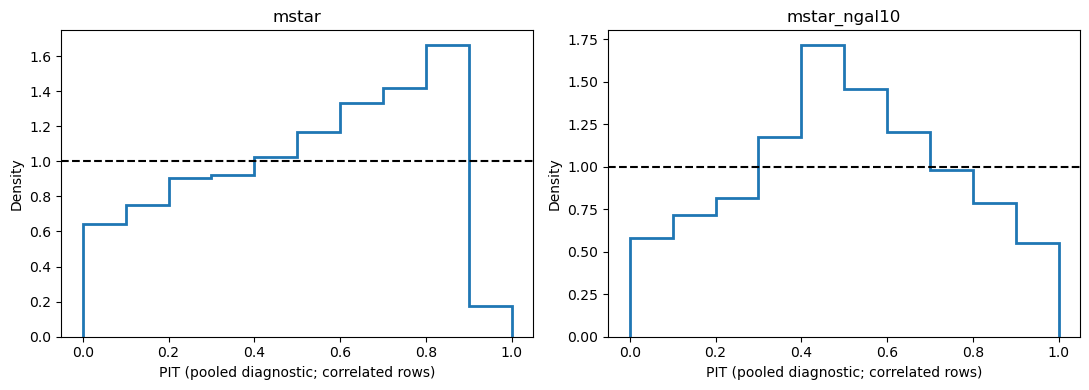

,N,delta_NLL,delta_Brier,delta_W68_dex
snapshot,,,,
6,3,-0.617198,-0.204861,-0.621602
7,20,-0.074162,-0.072240,-0.339720
8,43,-0.166115,-0.073210,-0.326174
9,91,-0.348823,-0.089108,-0.486831
10,168,-0.357861,-0.088156,-0.483676
11,244,-0.381486,-0.098845,-0.480475
12,300,-0.430882,-0.097905,-0.505269
13,300,-0.429215,-0.105940,-0.555137
14,300,-0.464710,-0.113633,-0.573060


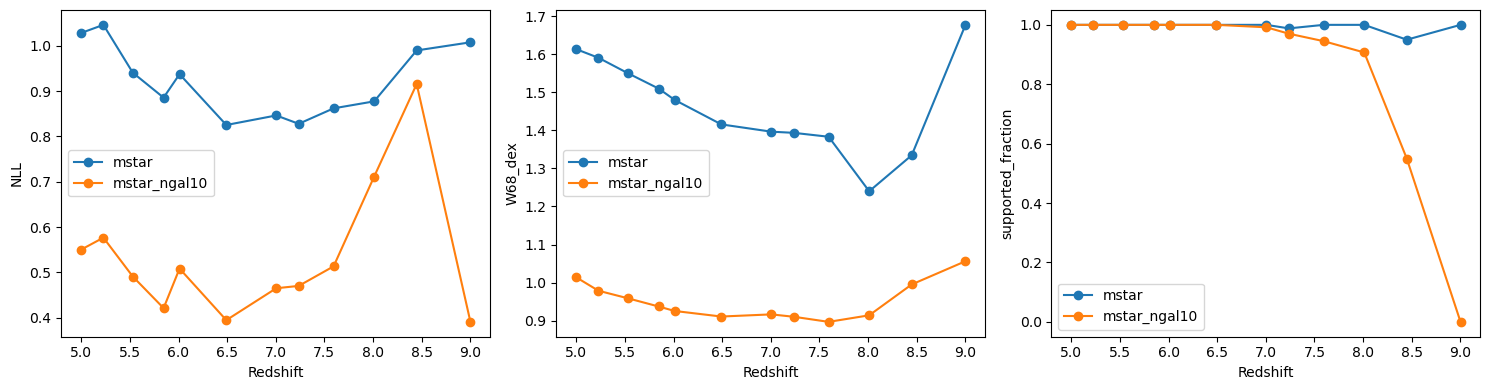

In [12]:
test_predictions, validation = evaluate(train, test, selected, TEST_CAP_PER_SNAP)
test_predictions.to_csv(RESULTS/'test_predictions.csv', index=False)
validation.to_csv(RESULTS/'validation.csv', index=False)
display(validation)
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for ax, name in zip(axes, FEATURE_SETS):
    pit = test_predictions.loc[test_predictions.feature_set.eq(name), 'pit']
    ax.hist(pit, bins=np.linspace(0,1,11), density=True, histtype='step', linewidth=2)
    ax.axhline(1, color='k', linestyle='--')
    ax.set(xlabel='PIT (pooled diagnostic; correlated rows)', ylabel='Density', title=name)
fig.tight_layout()
fig.savefig(RESULTS/'pit.png', dpi=160)
plt.show()
import scipy, sklearn
settings['versions'] = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                            scipy=scipy.__version__, sklearn=sklearn.__version__)
settings['selected'] = selected
settings['inference_uses'] = 'training only; no refit on test'
(RESULTS/'run_metadata.json').write_text(json.dumps(settings, indent=2))

keys = ['snapshot','SubhaloID','GroupID_z0']
paired = test_predictions.query("feature_set == 'mstar'").merge(
    test_predictions.query("feature_set == 'mstar_ngal10'"), on=keys,
    suffixes=('_mstar','_env'), validate='one_to_one')
assert len(paired)*2 == len(test_predictions)
for metric in ['nll','brier','W68_dex']:
    paired['delta_'+metric] = paired[metric+'_env']-paired[metric+'_mstar']
paired.to_csv(RESULTS/'paired_test_comparison.csv', index=False)
comparison = paired.groupby('snapshot').agg(
    N=('SubhaloID','size'), delta_NLL=('delta_nll','mean'),
    delta_Brier=('delta_brier','mean'), delta_W68_dex=('delta_W68_dex','mean'))
comparison.to_csv(RESULTS/'comparison_by_snapshot.csv')
display(comparison)
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, metric in zip(axes, ['NLL','W68_dex','supported_fraction']):
    for name, group in validation.groupby('feature_set'):
        group = group.sort_values('redshift')
        ax.plot(group.redshift, group[metric], marker='o', label=name)
    ax.set(xlabel='Redshift', ylabel=metric)
    ax.legend()
fig.tight_layout()
fig.savefig(RESULTS/'model_comparison.png', dpi=160)
plt.show()


## 入力例：同じ銀河に環境情報を加える
ngalは実測定義に従った非負整数を指定してください。例の値は特定の観測銀河を表しません。範囲内でもESS等が不足すれば停止します。まず環境ヒストグラムで分布を確認してください。
観測赤方偏移誤差や投影カウントを、この3D球カウントと同一視しないでください。

入力例の `ngal=20` は、実データでは一方の補間時刻でESS_host≈9.62となり、基準10を満たしませんでした。
末尾セルは `DIAGNOSTIC_PREVIEW=True` として両曲線を診断表示します。基準未達の曲線は点線・UNSUPPORTED表示で、
確かな事後分布として解釈しないでください。時刻別のESSと範囲判定を表・CSVで確認できます。
`model.posterior()` の通常呼び出しは引き続き標本不足で停止します。
`DIAGNOSTIC_PREVIEW=False` なら末尾セルも厳格に停止します。帯域幅や標本不足の閾値は変更していません。


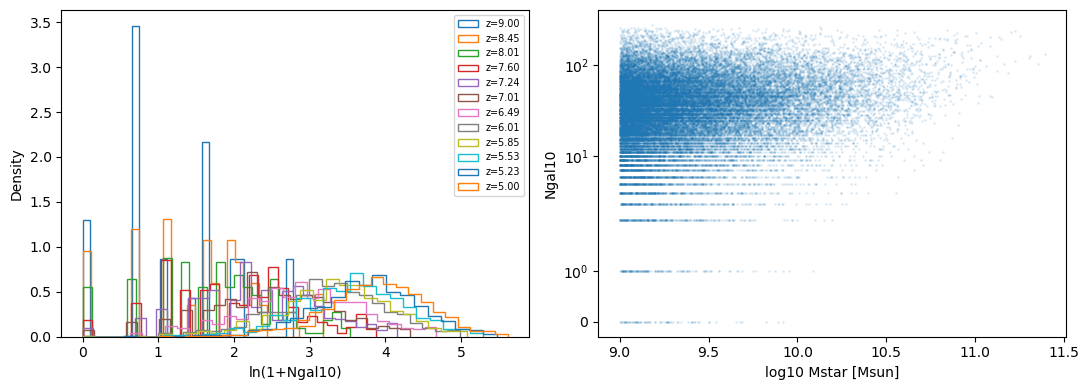

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for snap, group in train.groupby('snapshot'):
    axes[0].hist(group.log1pNgal10, bins=30, histtype='step', density=True,
                 label=f'z={group.redshift.iloc[0]:.2f}')
axes[0].set(xlabel='ln(1+Ngal10)', ylabel='Density')
axes[0].legend(fontsize=7)
axes[1].scatter(train.logMstar, train.Ngal10, s=1, alpha=.1)
axes[1].set(xlabel='log10 Mstar [Msun]', ylabel='Ngal10', yscale='symlog')
fig.tight_layout()
fig.savefig(RESULTS/'environment_support.png', dpi=160)
plt.show()


## 複数QUERYを重ねて比較
`QUERIES` の各辞書が1つの入力条件です。初期値は2パターンで、3つ以上にも増やせます。
入力条件ごとに色を変え、線種で分布の種類を区別します。両パネルで全曲線に共通の質量グリッドを使います。
凡例に赤方偏移・恒星質量・SFRまたは周辺銀河数を表示し、比較表・全PDF/CDF・設定JSON・図を保存します。
`SHOW_INTERVALS=True` で68%帯と中央値も表示できます。
標本不足の曲線は点線でUNSUPPORTEDと明示し、時刻別診断表も保存します。診断表示を止めるには `DIAGNOSTIC_PREVIEW=False` にします。


In [ ]:
model = LatentHostModel(train, selected, MODEL_LOGMSTAR_MIN)
# Add/remove dictionaries to compare any number of inputs; values here are examples.
QUERIES = [
    {'z': 8.0, 'logMstar': 9.5, 'ngal': 20},
    {'z': 8.0, 'logMstar': 9.5, 'ngal': 50},
]
SHOW_INTERVALS = False  # Optional central 68% bands and medians; off to avoid clutter.
if not QUERIES:
    raise ValueError('QUERIES must contain at least one input')
curves, query_labels = [], []
# Strict model.posterior() behavior is unchanged; preview preserves failed flags.
DIAGNOSTIC_PREVIEW = True
STYLES = {'Mstar only': '-', 'Mstar + Ngal10': '--'}
for qi, query in enumerate(QUERIES):
    query_labels.append(f"Q{qi+1}: z={query['z']:g}, logMstar={query['logMstar']:g}, Ngal10={query['ngal']}")
    p_mass = model.posterior(z=query['z'], logMstar=query['logMstar'],
                             check_support=not DIAGNOSTIC_PREVIEW)
    p_env = model.posterior(**query, check_support=not DIAGNOSTIC_PREVIEW)
    curves.extend([(qi, 'Mstar only', p_mass), (qi, 'Mstar + Ngal10', p_env)])
print('Support: ESS_galaxy >= 20, ESS_host >= 10, nearest distance <= 3, within range.')

# Use one grid for every query/model, including different smoothing widths.
grid = np.linspace(min(p.means.min()-8*p.width for _,_,p in curves),
                   max(p.means.max()+8*p.width for _,_,p in curves), 700)
fig, axes = plt.subplots(1, 2, figsize=(15,5))
summary_rows, density_tables, support_rows = [], [], []
for qi, name, p in curves:
    color = f'C{qi % 10}'
    supported = p.metadata.get('support_ok', True)
    style = STYLES[name] if supported else ':'
    label = f"{query_labels[qi]} | {name}"
    if not supported:
        label += ' [UNSUPPORTED: diagnostic only]'
    density = np.array([np.exp(p.logpdf(x)) for x in grid])
    cdf = np.array([p.cdf(x) for x in grid])
    axes[0].plot(grid, density, color=color, linestyle=style, label=label)
    axes[1].plot(grid, 1-cdf, color=color, linestyle=style, label=label)
    summary_rows.append(dict(query_index=qi+1, query=query_labels[qi], curve=name, **p.summary()))
    density_tables.append(pd.DataFrame(dict(query_index=qi+1, query=query_labels[qi],
        curve=name, logM0=grid, pdf_per_dex=density, cdf=cdf, support_ok=supported)))
    for ep in p.metadata.get('epochs', []):
        support_rows.append(dict(query_index=qi+1, query=query_labels[qi], curve=name, **ep))
    if SHOW_INTERVALS and name != 'Baseline':
        axes[0].axvspan(p.quantile(.16), p.quantile(.84), color=color, alpha=.07)
        axes[0].axvline(p.quantile(.5), color=color, alpha=.4, linewidth=.8)
axes[0].set(xlabel='log10 M0 [Msun]', ylabel='PDF [dex^-1]')
axes[1].set(xlabel='log10 threshold mass [Msun]', ylabel='P(M0 >= threshold)', ylim=(0,1))
for ax in axes:
    ax.legend(fontsize=8)
if any(not p.metadata.get('support_ok', True) for _,_,p in curves):
    fig.suptitle('Dotted unsupported curves are diagnostic only', color='crimson')
else:
    fig.suptitle('Multiple input queries: conditional host-mass distributions')
fig.tight_layout()
batch_id = hashlib.sha256(json.dumps(QUERIES, sort_keys=True).encode()).hexdigest()[:12]
summary_table = pd.DataFrame(summary_rows)
display(summary_table)
summary_table.to_csv(RESULTS/f'queries_{batch_id}_summary.csv', index=False)
pd.concat(density_tables, ignore_index=True).to_csv(RESULTS/f'queries_{batch_id}_pdf.csv', index=False)
if support_rows:
    support_table = pd.DataFrame(support_rows)
    display(support_table)
    support_table.to_csv(RESULTS/f'queries_{batch_id}_support.csv', index=False)
(RESULTS/f'queries_{batch_id}.json').write_text(json.dumps(
    dict(queries=QUERIES, summaries=summary_rows), indent=2))
fig.savefig(RESULTS/f'queries_{batch_id}.png', dpi=160)
plt.show()
print('Results:', RESULTS.resolve())


## 解釈と再実行
- KDEの区間はシミュレーション内の条件付き分布です。モデル不確実性・有限標本・宇宙分散は別途評価が必要です。
- 帯域幅候補端で最適になった場合は探索範囲の限界を確認します。testを見て再調整した場合、以降のtest評価は未使用評価ではありません。
- 3D環境を追加すると疎な領域が増え得ます。支持率低下を含めて評価してください。
- 環境キャッシュは時刻単位で再開可能。QUERYのみの変更なら末尾セルだけ再実行できます。
- 09のsplit.csvと比較する場合、同じ元カタログ・質量下限・SEEDであることを確認してください。